# Notebook 06: Exploring the existing results

**Goal (about 1.5 hours):** read the results Michael's pipeline produced for every station, understand the bookkeeping (why each event did or did not yield a number), and make the standard summary plots: histograms and rose diagrams.

From here on you work with the results CSVs in `results/`. One row per catalog event per station; nothing is dropped, the `stage` column says where each event stopped.

> **Note on STAR.** This notebook uses the original results files. STAR's was computed before its exchanged vertical and north channels were found (notebook 02), so its phi values (and its filtered set) come from the channels as labelled: the "horizontals" the pipeline used were really the vertical and east records. The research pipeline has since re-run STAR on waveforms rotated to true Z/N/E, with the 33 events whose S wave clipped removed (`paths.station_results_csv("STAR", oriented=True)`; notebook 07 uses it). That changes the filtered set almost completely: 194 events instead of 110, only 44 of them in common. The tight east-west cluster next to the back azimuth (66 of the 110 fast directions between 80 and 100 degrees, 70 percent of them within 20 degrees of the back azimuth) goes away; corrected, 5 fast directions fall between 80 and 100 degrees, and 136 of the 194 cluster north-north-east between 20 and 40 degrees (axial mean 34 degrees, circular standard deviation 16). Use STAR's rows here to learn the tools, not to draw conclusions; the other stations' 2025 channels are oriented as their metadata say, and their results did not change.

In [1]:
# --- setup: make the repo importable and keep figures inline ---
import sys, warnings
from pathlib import Path
REPO = Path.cwd().parent if (Path.cwd() / "../rainier_sws").exists() else Path.cwd()
sys.path.insert(0, str(REPO))
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
from rainier_sws import paths, data, measure, quality, stats
print("repo:", REPO)

repo: /Users/mhemmett/Seismology/rainier-sws-tutorials


In [2]:
import glob
STATIONS = ["STAR", "RCM", "MILD", "LON", "PANH", "OBSR", "PARA", "RER", "COPP"]
res = {s: pd.read_csv(paths.station_results_csv(s)) for s in STATIONS}
res["STAR"].head(3)

,evid,station,stage,back_azimuth,rectilinearity,incidence_angle_jurkevics,incidence_angle,travel_time_s,snr_horizontal,filter_band,...,phi_error,dt_error,quality,dominant_period,success,pct_anisotropy,datetime,magnitude,error,traceback
0,61504363,STAR,ok,80.287841,0.644608,36.952068,25.207142,1.822654,2.539548,"(5.0, 15.0)",...,2.0,0.01,0.053923,0.091545,True,1.097301,2025-07-08T15:24:37.709999084+00:00,-0.44,NaN,NaN
1,61504373,STAR,fail_snr,85.530214,0.699192,36.697966,25.044442,1.650617,1.726128,"(10.0, 45.0)",...,NaN,NaN,NaN,NaN,NaN,NaN,2025-07-08T15:38:45.819999695+00:00,0.31,NaN,NaN
2,61504388,STAR,ok,87.119563,0.729471,38.116861,26.039246,1.766310,2.551091,"(3.0, 5.0)",...,31.0,0.03,0.000000,0.214825,True,2.264608,2025-07-08T15:47:51.469997406+00:00,0.36,NaN,NaN


## 1. The funnel: attempted, successful, filtered

Three numbers per station. "Successful" means the pipeline reached the end and returned finite phi and dt. "Filtered" means the measurement also passed the post-processing filter (`rainier_sws/quality.py`). Compare with the README's *Known facts about the research results*.

In [3]:
funnel = pd.DataFrame({s: quality.funnel(r) for s, r in res.items()}).T
funnel

,attempted,successful,filtered
STAR,903,709,110
RCM,509,274,32
MILD,685,107,24
LON,1172,670,38
PANH,414,0,0
OBSR,139,1,0
PARA,749,0,0
RER,450,0,0
COPP,348,0,0


Text(0.5, 1.0, "Where each station's events stopped")

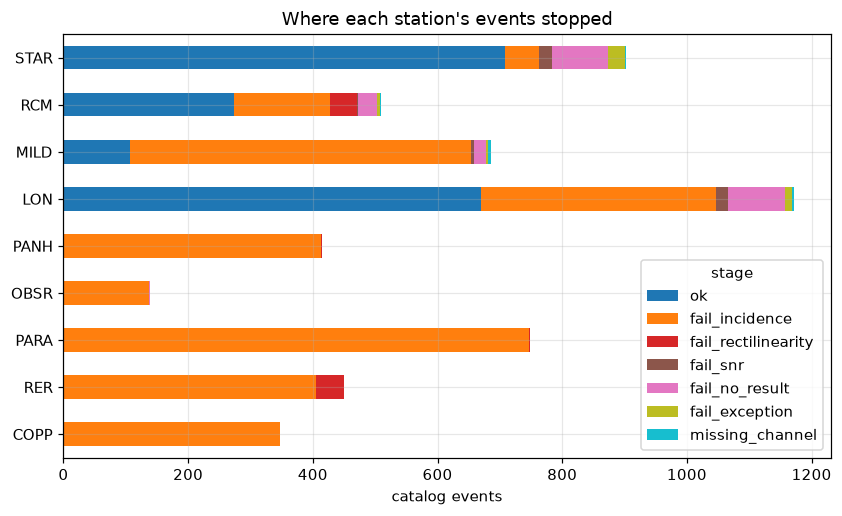

In [4]:
stages = pd.DataFrame({s: quality.stage_counts(r) for s, r in res.items()}).fillna(0).astype(int).T
stages = stages[["ok", "fail_incidence", "fail_rectilinearity", "fail_snr", "fail_no_result", "fail_exception", "missing_channel"]]
ax = stages.plot.barh(stacked=True, figsize=(9, 5), colormap="tab10"); ax.invert_yaxis()
ax.set_xlabel("catalog events"); ax.set_title("Where each station's events stopped")

This is the picture behind the first of the README's *Known facts*: PANH, OBSR, PARA, RER and COPP produce almost nothing, and the plot shows exactly why, **essentially every event fails the incidence-angle gate** (RER also loses about 45 events to the rectilinearity check, which comes first). That is a known, understood outcome, not a bug to find. These stations sit far enough from the swarm that, through the velocity model used for ray tracing, every S wave arrives at more than 45 degrees from vertical.

Whether that is the *right* conclusion depends on two choices made upstream: the velocity model that produced the angles, and the 45-degree cutoff itself. Both are thresholds to benchmark (notebook 07), not facts.

## 2. Distributions of the measured quantities (STAR)

Before any filtering, look at everything the pipeline returned. Histograms of phi, dt, their formal errors, the quality score and SNR tell you what the raw population looks like and where the post-processing cuts fall.

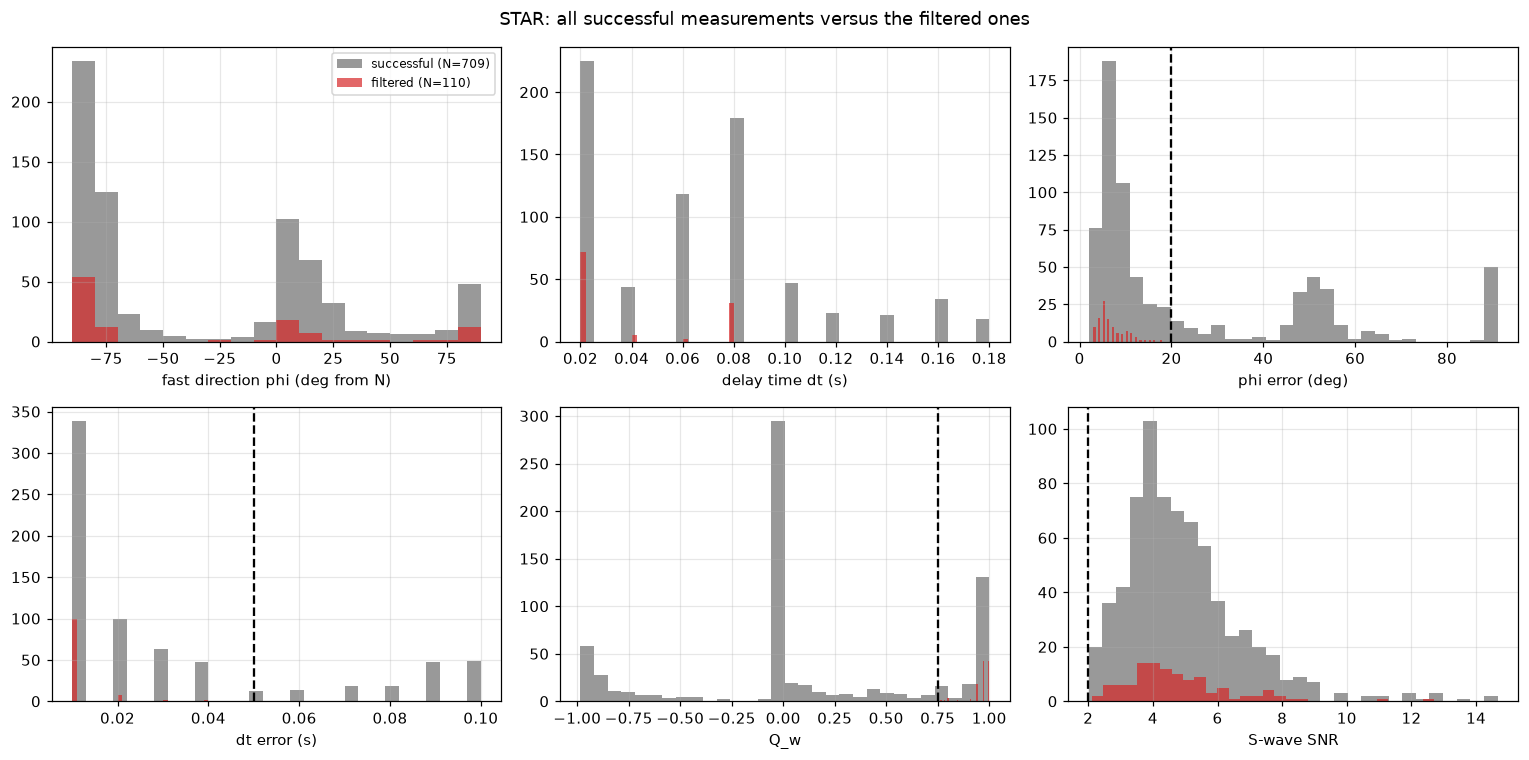

In [5]:
def hist_panel(r, title):
    ok = quality.successful(r); kept = quality.post_filtered(r)
    g = quality.DEFAULT_POST
    cols = [("phi", "fast direction phi (deg from N)", None), ("dt", "delay time dt (s)", None),
            ("phi_error", "phi error (deg)", g.phi_error_max), ("dt_error", "dt error (s)", g.dt_error_max),
            ("quality", "Q_w", g.qw_min), ("snr_horizontal", "S-wave SNR", g.snr_min)]
    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for ax, (c, lab, cut) in zip(axes.ravel(), cols):
        bins = 30 if c != "phi" else np.arange(-90, 91, 10)
        ax.hist(ok[c].dropna(), bins=bins, color="0.6", label=f"successful (N={len(ok)})")
        ax.hist(kept[c].dropna(), bins=bins, color="tab:red", alpha=0.7, label=f"filtered (N={len(kept)})")
        if cut is not None: ax.axvline(cut, color="k", ls="--")
        ax.set_xlabel(lab)
    axes[0, 0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout()
hist_panel(res["STAR"], "STAR: all successful measurements versus the filtered ones")

Read the panels together. Many successful measurements have large phi errors or low Q_w; the post-processing filter removes most of them. What survives has dt of 0.02 s (two samples!) for 72 of the 110, a second group of 31 at 0.08 s and only 7 in between (dt comes in steps of 0.02 s), and phi clustered near plus or minus 90, i.e. east-west, with a smaller group near 0. Whether a one-sample delay is physically meaningful is a fair question to keep asking.

## 3. Rose diagrams

The standard display for fast directions is a rose diagram: a histogram on a circle, mirrored because phi is an axis. Here is a small function; use it for every station from now on.

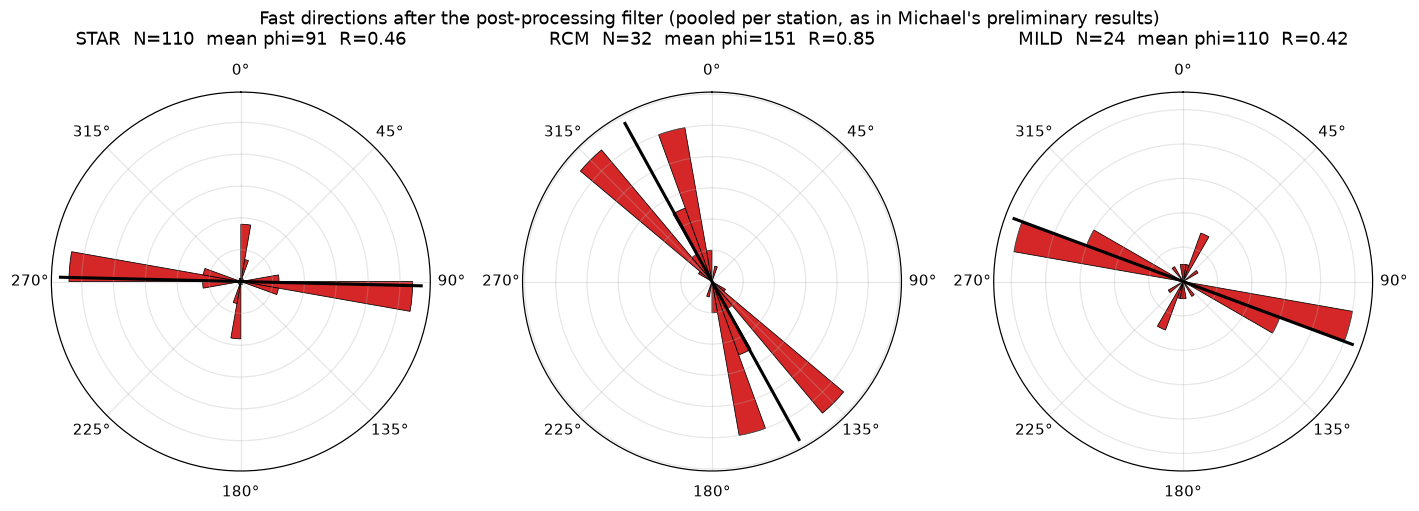

In [6]:
def rose(ax, phi_deg, bin_deg=10, color="tab:red", title=""):
    phi = measure.phi_0_180(np.asarray(phi_deg))
    bins = np.arange(0, 181, bin_deg)
    counts, _ = np.histogram(phi, bins=bins)
    theta = np.deg2rad(np.concatenate([bins[:-1], bins[:-1] + 180]))
    ax.bar(theta, np.concatenate([counts, counts]), width=np.deg2rad(bin_deg), bottom=0, color=color, edgecolor="k", lw=0.5, align="edge")
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_yticklabels([])
    ax.set_title(title, pad=12)

fig = plt.figure(figsize=(13, 4.5))
for i, s in enumerate(["STAR", "RCM", "MILD"]):
    kept = quality.post_filtered(res[s])
    m, R = stats.axial_mean(kept.phi)
    ax = fig.add_subplot(1, 3, i + 1, projection="polar")
    rose(ax, kept.phi, title=f"{s}  N={len(kept)}  mean phi={m:.0f}  R={R:.2f}")
    ax.plot([np.deg2rad(m), np.deg2rad(m + 180)], [ax.get_ylim()[1]] * 2, "k-", lw=2)
fig.suptitle("Fast directions after the post-processing filter (pooled per station, as in Michael's preliminary results)")
plt.tight_layout()

`R` is the mean resultant length (0 = no preferred axis, 1 = all identical). STAR's roughly east-west preference is clear (but see the note at the top). RCM, with far fewer events, is the most tightly clustered of the three (R = 0.85, about 151 degrees, north-north-west); MILD has the fewest events and a broader spread around west-north-west. The black bar is the axial mean. None of these has an error bar yet; that is notebook 07.

## 4. Does the answer depend on where the earthquake is?

Plot the filtered phi against back azimuth. If fast directions were a property of the rock under the station they would not depend on where the wave came from. If they track the back azimuth, suspect nulls or ray-path effects.

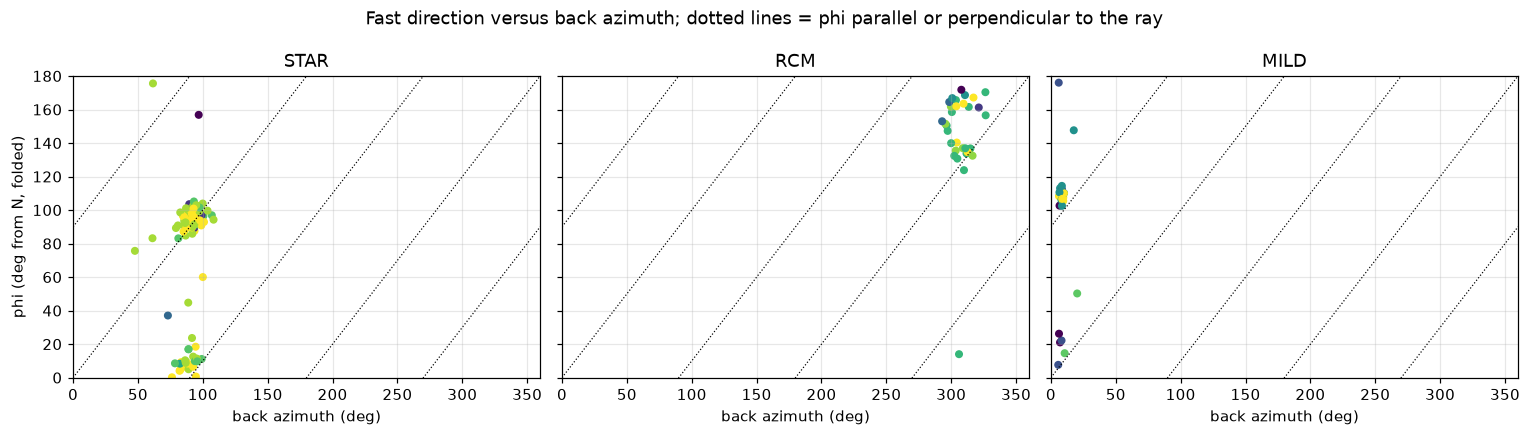

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, s in zip(axes, ["STAR", "RCM", "MILD"]):
    kept = quality.post_filtered(res[s])
    ax.scatter(kept.back_azimuth, measure.phi_0_180(kept.phi), c=kept.quality, cmap="viridis", s=18)
    for off in (-270, -180, -90, 0, 90, 180):      # every fold of 'parallel' and 'perpendicular'
        ax.plot([0, 360], [off, off + 360], "k:", lw=0.8)
    ax.set_xlabel("back azimuth (deg)"); ax.set_title(s); ax.set_ylim(0, 180); ax.set_xlim(0, 360)
axes[0].set_ylabel("phi (deg from N, folded)")
fig.suptitle("Fast direction versus back azimuth; dotted lines = phi parallel or perpendicular to the ray")
plt.tight_layout()

At STAR almost all rays come from one back azimuth (about 90 degrees), so this plot cannot distinguish "the rock is anisotropic" from "phi equals the back azimuth". That is a limitation of the geometry, not of the method, and it is why adding stations with different geometry matters.

## 5. Time: does anything change during the swarm?

The scientific question is whether anisotropy changed as fluids moved. Plot filtered dt and phi against origin time with a running median.

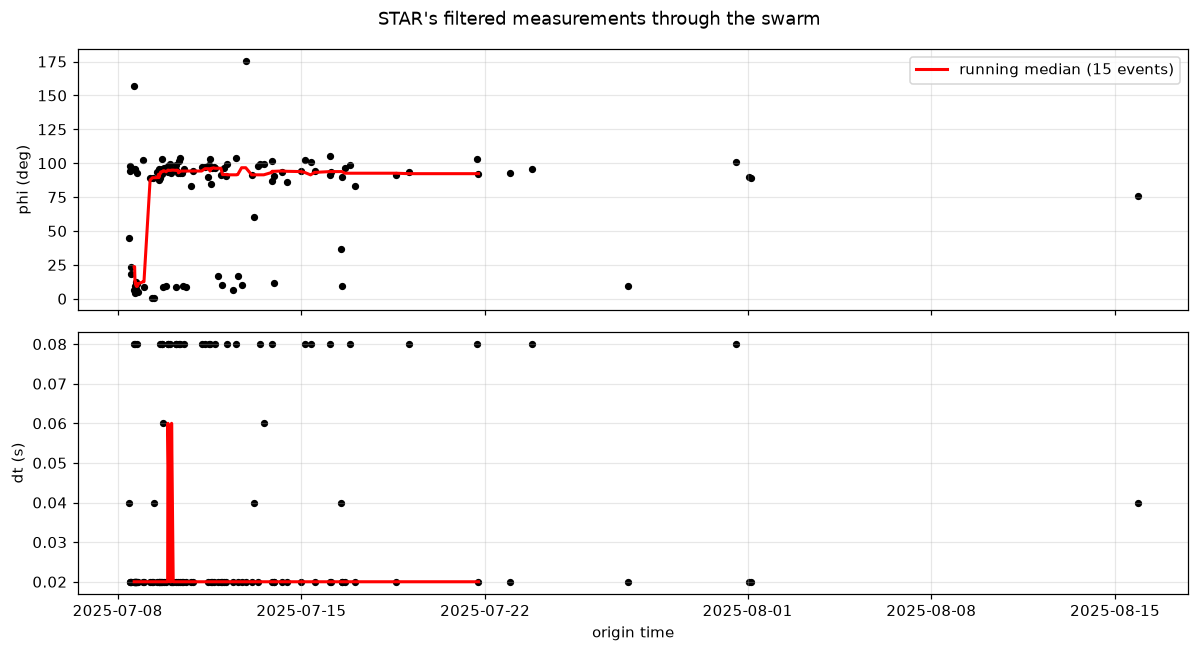

In [8]:
kept = quality.post_filtered(res["STAR"]).copy()
kept["time"] = pd.to_datetime(kept.datetime, utc=True, format="ISO8601")
kept = kept.sort_values("time")
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].scatter(kept.time, measure.phi_0_180(kept.phi), s=14, c="k"); axes[0].set_ylabel("phi (deg)")
axes[1].scatter(kept.time, kept.dt, s=14, c="k"); axes[1].set_ylabel("dt (s)")
for ax, col in zip(axes, [measure.phi_0_180(kept.phi), kept.dt]):
    ax.plot(kept.time, pd.Series(np.asarray(col)).rolling(15, center=True).median().values, "r-", lw=2, label="running median (15 events)")
axes[0].legend(); axes[1].set_xlabel("origin time"); fig.suptitle("STAR's filtered measurements through the swarm")
plt.tight_layout()

With 110 points and errors of several degrees and 0.01 s, is any trend here distinguishable from noise? You cannot answer that without an uncertainty estimate, which is the next notebook.

## 6. Exercises

1. Make `hist_panel` for RCM and MILD. Which post-processing cut removes the most events at each station?
2. Add LON to the rose figure. LON used the data-derived (Jurkevics) incidence angle instead of the ray-traced one; does its rose look like the others?
3. For PANH, histogram `incidence_angle` (ray-traced) and `incidence_angle_jurkevics`. How far above 45 degrees are the events? Would a 60-degree cutoff rescue any? (Careful: rescued is not the same as valid.)
4. Compute percent anisotropy (`pct_anisotropy`, dt divided by travel time) summary statistics per station after the post-processing filter. Which station is "most anisotropic", and do you believe it given the sample sizes?

Next: `07_uncertainty_and_thresholds.ipynb`.

## 7. Example solutions

One way to do each exercise. Try them yourself first. STAR's rows predate the orientation fix (the note at the top); the stations used here (RCM, MILD, LON, PANH) are oriented as their metadata say.

### Exercise 1: `hist_panel` for RCM and MILD, and which cut removes the most

The histograms show where the cuts fall; to say which one *removes the most*, count, among the successful measurements, how many fail each post-processing cut. A measurement can fail several cuts at once, so also count the ones that fail **only** that cut: those are the events that cut alone is responsible for.

RCM: 274 successful, 32 pass the filter
                  fail this cut  fail only this cut
SNR < 2.0                     0                   0
Q_w < 0.75                  191                  60
dt_error > 0.05              59                   1
phi_error > 20.0            147                  33
dt > half period             67                   8 

MILD: 107 successful, 24 pass the filter
                  fail this cut  fail only this cut
SNR < 2.0                     0                   0
Q_w < 0.75                   59                   9
dt_error > 0.05              43                   1
phi_error > 20.0             61                   9
dt > half period             20                   3 



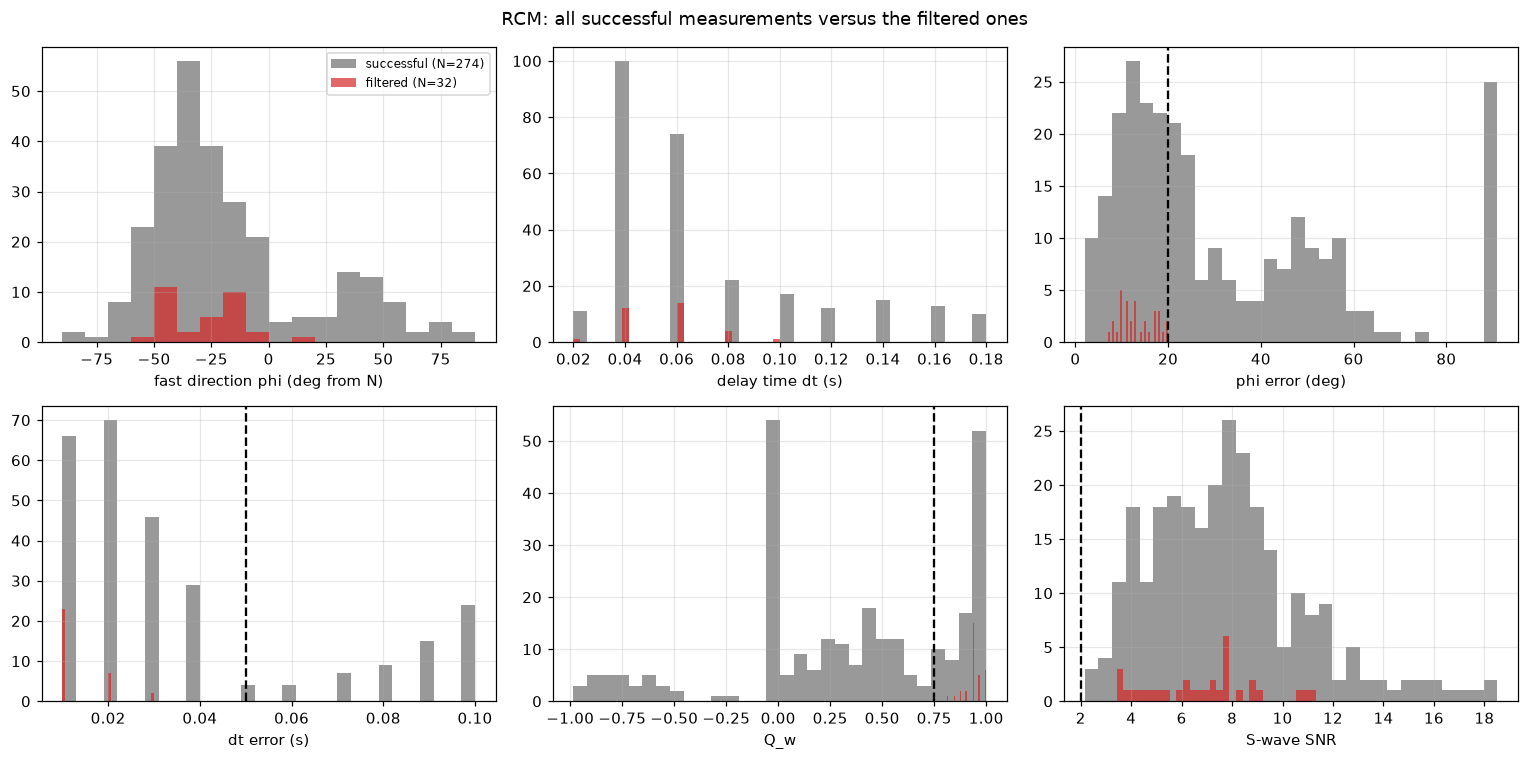

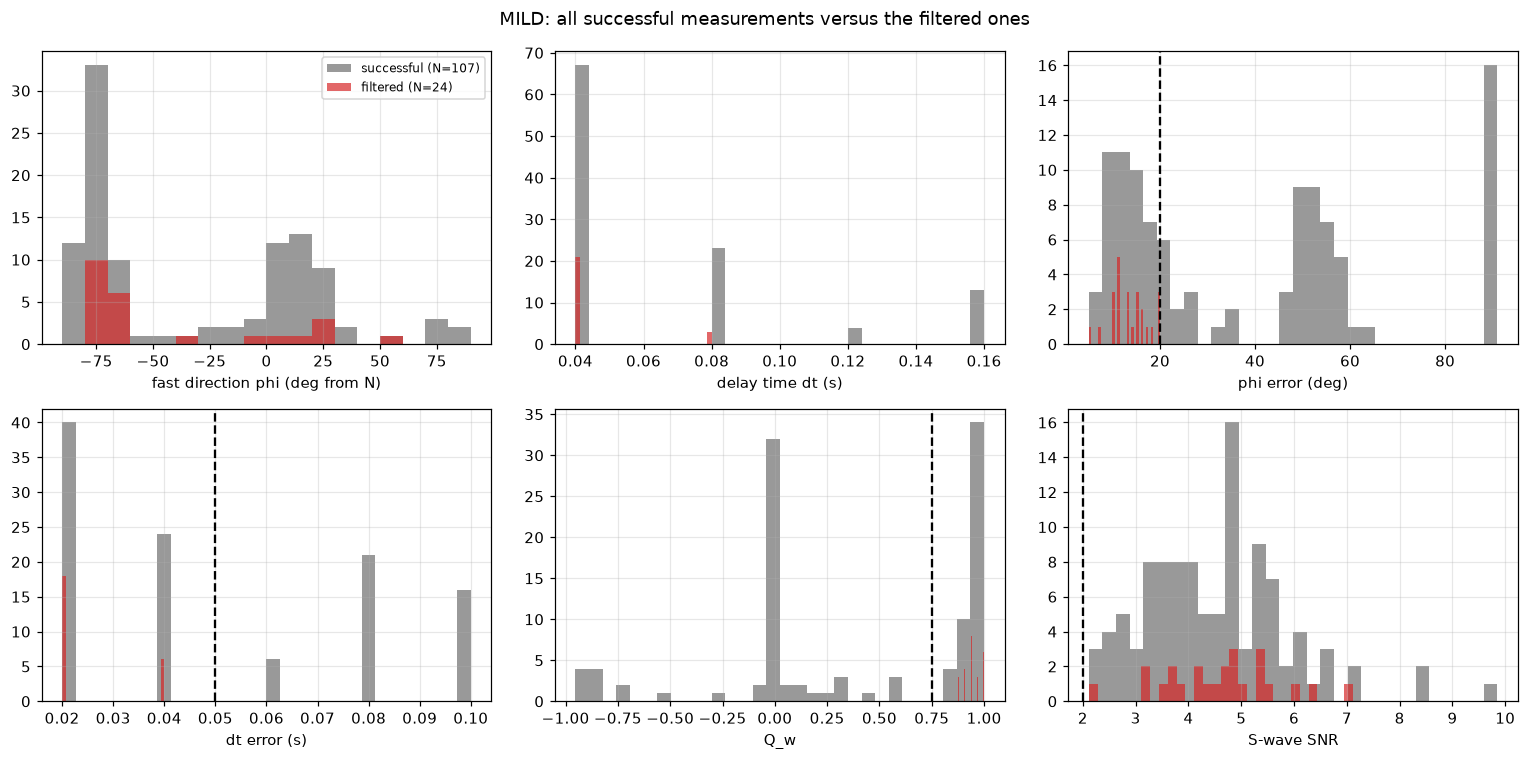

In [9]:
hist_panel(res["RCM"], "RCM: all successful measurements versus the filtered ones")
hist_panel(res["MILD"], "MILD: all successful measurements versus the filtered ones")

g = quality.DEFAULT_POST
def cut_table(r):
    ok = quality.successful(r)
    fails = pd.DataFrame({
        f"SNR < {g.snr_min}": ok.snr_horizontal < g.snr_min,
        f"Q_w < {g.qw_min}": ok.quality < g.qw_min,
        f"dt_error > {g.dt_error_max}": ok.dt_error > g.dt_error_max,
        f"phi_error > {g.phi_error_max}": ok.phi_error > g.phi_error_max,
        "dt > half period": ok.dt > ok.dominant_period * g.dt_period_fraction,
    })
    only = fails[fails.sum(axis=1) == 1]
    return pd.DataFrame({"fail this cut": fails.sum(), "fail only this cut": only.sum()})

for s in ["RCM", "MILD"]:
    f = quality.funnel(res[s])
    print(f"{s}: {f.successful} successful, {f.filtered} pass the filter")
    print(cut_table(res[s]).to_string(), "\n")

**Q_w and phi_error do almost all the work.** At RCM, 191 of the 274 successful measurements have Q_w below 0.75 and 147 have phi errors above 20 degrees; 60 and 33 fail on that cut alone. At MILD the same two lead (61 and 59 of 107). The **SNR cut removes nothing** at either station: the pre-processing gate already required SNR of at least 2, so the post-processing SNR cut is redundant with the default thresholds. dt_error almost never matters on its own (one event at each station), because a large dt error comes with a large phi error and a low Q_w.

The cuts overlap heavily. Of RCM's 242 rejected measurements only 102 are rejected by a single cut, and of MILD's 83 only 22, so loosening any one threshold lets in far fewer events than its "fail this cut" count suggests. Things to notice in the histograms: the spike of phi errors at 90 degrees (the error contour filling the whole grid, i.e. no constraint at all), the pile-up of Q_w exactly at 0, and MILD's delays coming only in multiples of 0.04 s, where the others step by 0.02 s.

### Exercise 2: LON on the rose figure

The same loop as section 3, with LON as a fourth panel. Remember what is different about LON: its ray-traced incidence angles are all above 45 degrees (60 to 80), so with the research gate nothing would survive; it was run with the Jurkevics angle from the P-wave particle motion instead.

LON ray-traced incidence: 62 to 81 deg; Jurkevics: median 36 deg, 32% above 45
STAR  N= 110  median back azimuth    92 deg  Rayleigh p = 2.0e-11
RCM   N=  32  median back azimuth   307 deg  Rayleigh p = 2.4e-10
MILD  N=  24  median back azimuth     8 deg  Rayleigh p = 1.3e-02
LON   N=  38  median back azimuth    16 deg  Rayleigh p = 2.7e-08


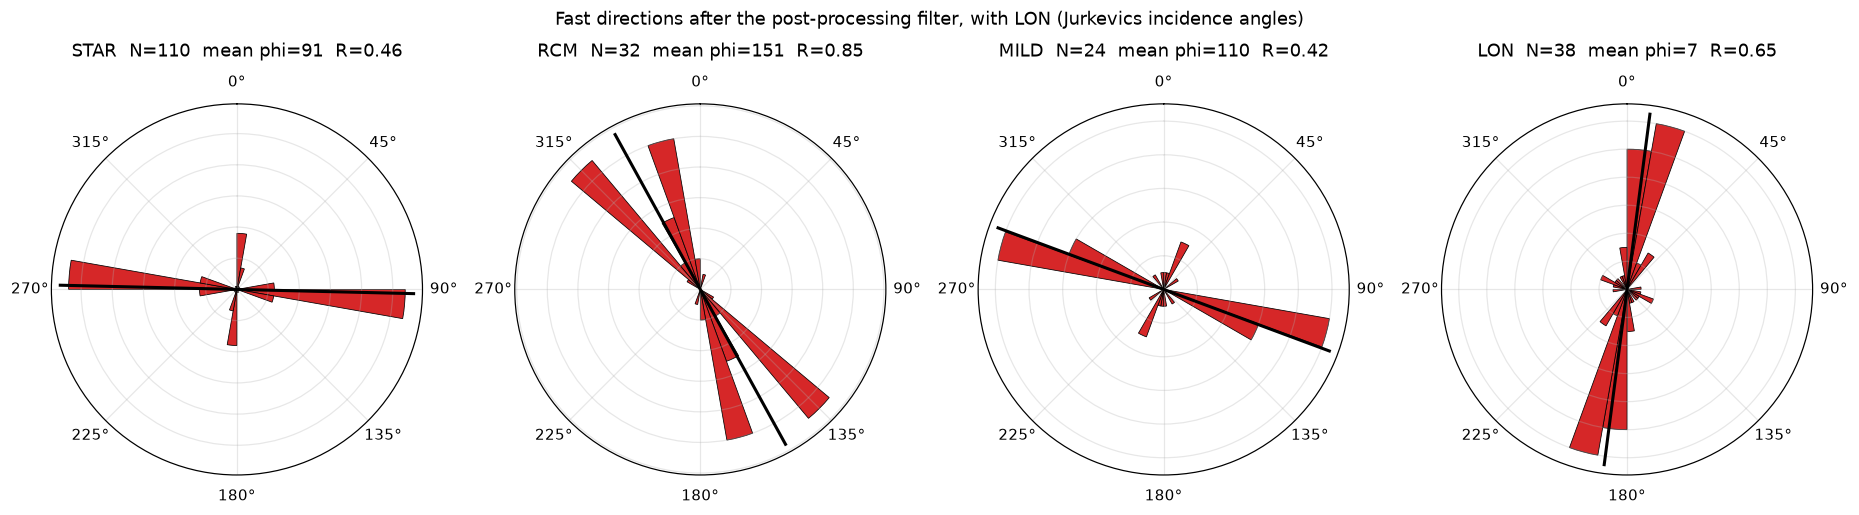

In [10]:
fig = plt.figure(figsize=(17, 4.8))
for i, s in enumerate(["STAR", "RCM", "MILD", "LON"]):
    kept = quality.post_filtered(res[s])
    m, R = stats.axial_mean(kept.phi)
    ax = fig.add_subplot(1, 4, i + 1, projection="polar")
    rose(ax, kept.phi, title=f"{s}  N={len(kept)}  mean phi={m:.0f}  R={R:.2f}")
    ax.plot([np.deg2rad(m), np.deg2rad(m + 180)], [ax.get_ylim()[1]] * 2, "k-", lw=2)
fig.suptitle("Fast directions after the post-processing filter, with LON (Jurkevics incidence angles)")
plt.tight_layout()

lon = res["LON"]
print(f"LON ray-traced incidence: {lon.incidence_angle.min():.0f} to {lon.incidence_angle.max():.0f} deg; "
      f"Jurkevics: median {lon.incidence_angle_jurkevics.median():.0f} deg, "
      f"{(lon.incidence_angle_jurkevics > 45).mean():.0%} above 45")
for s in ["STAR", "RCM", "MILD", "LON"]:
    kept = quality.post_filtered(res[s]); z, p_val = stats.rayleigh_test(measure.phi_0_180(kept.phi))
    print(f"{s:5s} N={len(kept):4d}  median back azimuth {kept.back_azimuth.median():5.0f} deg  Rayleigh p = {p_val:.1e}")

**No, and it should not be compared with them directly.** LON's rose is tight (R = 0.65) around 7 degrees, almost north-south, where RCM points about 151, MILD about 110 and STAR (pre-fix) 91. Two reasons to be careful:

- **Different incidence angles.** By the velocity model, every LON ray arrives 62 to 81 degrees from vertical, far outside the shear-wave window; it only produced measurements because it was run with the Jurkevics angles (median 36 degrees). So LON's numbers rest on the opposite assumption from the other stations'.
- **Null geometry.** LON's mean fast direction (7) is about 9 degrees from its median back azimuth (16): the fast axis lies along the ray, the same geometry as STAR's near-nulls. MILD's (110 against a back azimuth of 8) is about 12 degrees from perpendicular, the other null geometry. Only RCM's fast axis sits clearly off both, about 24 degrees from its back azimuth (307).

All four roses pass the Rayleigh test with tiny p-values, so all four have a preferred axis. A tight rose is not the same as a correct one: a population of nulls also gives a tight rose, pointing along the ray.

### Exercise 3: PANH's incidence angles

ray-traced: min 52.6, median 68.7, max 84.1 deg; median 24 deg above the 45-degree gate
  cutoff 45 deg would let through   0 of 414 events
  cutoff 50 deg would let through   0 of 414 events
  cutoff 55 deg would let through   1 of 414 events
  cutoff 60 deg would let through   8 of 414 events
Jurkevics: median 27.5 deg, 394 events at or below 45


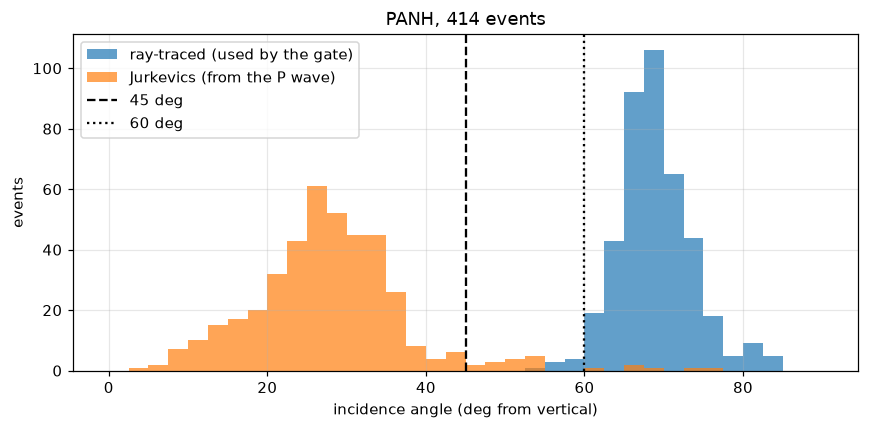

In [11]:
panh = res["PANH"]
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0, 91, 2.5)
ax.hist(panh.incidence_angle, bins=bins, color="tab:blue", alpha=0.7, label="ray-traced (used by the gate)")
ax.hist(panh.incidence_angle_jurkevics, bins=bins, color="tab:orange", alpha=0.7, label="Jurkevics (from the P wave)")
for cut, ls in [(45, "--"), (60, ":")]:
    ax.axvline(cut, color="k", ls=ls, label=f"{cut} deg")
ax.set_xlabel("incidence angle (deg from vertical)"); ax.set_ylabel("events"); ax.legend()
ax.set_title(f"PANH, {len(panh)} events")
plt.tight_layout()

inc = panh.incidence_angle
print(f"ray-traced: min {inc.min():.1f}, median {inc.median():.1f}, max {inc.max():.1f} deg; "
      f"median {inc.median() - 45:.0f} deg above the 45-degree gate")
for cut in (45, 50, 55, 60):
    print(f"  cutoff {cut} deg would let through {(inc <= cut).sum():3d} of {len(inc)} events")
print(f"Jurkevics: median {panh.incidence_angle_jurkevics.median():.1f} deg, {(panh.incidence_angle_jurkevics <= 45).sum()} events at or below 45")

PANH's ray-traced angles run from 53 to 84 degrees, median 69: a typical event is 24 degrees past the gate. Raising the cutoff to 60 degrees would let through 8 of the 414 events, to 55 just one. The Jurkevics angles tell a completely different story: 394 of the 414 are at or below 45 degrees (median 27.5). Whether PANH has usable data at all depends entirely on which angle you believe, which is the velocity-model question of section 1 (a near-surface low-velocity layer bends rays towards the vertical, and a smooth model may not capture it).

*Rescued is not valid.* The textbook shear-wave window is sin⁻¹(Vs/Vp), about 35 degrees for Vp/Vs = 1.73; the 45-degree gate is already generous. At 55 to 60 degrees the free surface makes the S-wave particle motion elliptical even in an isotropic Earth, and a splitting measurement reads that ellipticity as a delay. Moving the cutoff to 60 adds 8 events and a systematic error.

### Exercise 4: percent anisotropy per station

`pct_anisotropy` is 100 × dt / travel time, so it inherits everything about dt: one sample of delay (0.01 s) over a 1 to 4 s travel time is already 0.25 to 1 percent. Report each station's median with a bootstrap interval, and N.

In [12]:
rows = []
for s in STATIONS:
    kept = quality.post_filtered(res[s])
    if len(kept) == 0 or "pct_anisotropy" not in kept:
        rows.append({"station": s, "N": 0}); continue
    a = kept.pct_anisotropy.dropna().to_numpy()
    med, lo, hi, _ = stats.bootstrap(a, np.median, ci=95)
    rows.append({"station": s, "N": len(a), "median %": med, "95% CI low": lo, "95% CI high": hi,
                 "mean %": a.mean(), "IQR": np.subtract(*np.percentile(a, [75, 25])),
                 "median dt (s)": kept["dt"].median(), "median travel time (s)": kept.travel_time_s.median()})
aniso = pd.DataFrame(rows).set_index("station")
aniso.round(2)

,N,median %,95% CI low,95% CI high,mean %,IQR,median dt (s),median travel time (s)
station,,,,,,,,
STAR,110,1.17,1.14,1.20,2.15,3.14,0.02,1.79
RCM,32,3.59,2.52,3.91,3.40,1.66,0.06,1.62
MILD,24,1.99,1.95,2.03,2.19,0.12,0.04,2.03
LON,38,0.56,0.54,0.56,0.68,0.04,0.02,3.67
PANH,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OBSR,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PARA,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RER,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
COPP,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


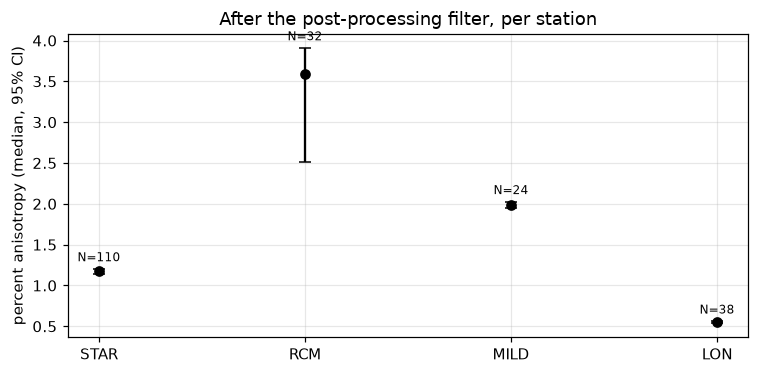

In [13]:
have = aniso[aniso.N > 0]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(have.index, have["median %"], yerr=[have["median %"] - have["95% CI low"], have["95% CI high"] - have["median %"]],
            fmt="o", color="k", capsize=4)
for x, (s, r) in enumerate(have.iterrows()):
    ax.annotate(f"N={int(r.N)}", (x, r["95% CI high"]), xytext=(0, 5), textcoords="offset points", ha="center", fontsize=8)
ax.set_ylabel("percent anisotropy (median, 95% CI)"); ax.set_title("After the post-processing filter, per station")
plt.tight_layout()

RCM looks the "most anisotropic" (median 3.6 percent, 95% interval 2.5 to 3.9, N = 32), then MILD (2.0), STAR (1.2) and LON (0.56). Do not believe the ranking yet; look at what the numbers are made of:

- **dt is quantized.** Filtered delays take only two to five distinct values per station (steps of 0.02 s, 0.04 s at MILD), and percent anisotropy is 100 × dt / travel time with a nearly constant travel time. Each median is essentially the most common number of samples of delay, divided by the ray's travel time.
- **The narrow intervals are artifacts.** 21 of MILD's 24 delays are 0.04 s and 32 of LON's 38 are 0.02 s, so resampling almost never moves the median. The bootstrap interval measures that, not whether 0.04 s is the true delay. RCM's wide interval comes from its delays splitting almost evenly between 0.04 s (12) and 0.06 s (14).
- **Ray length matters.** LON's travel times are about 3.7 s against 1.6 to 2.0 s for the summit stations, so the same delay gives half the percentage.
- **STAR's number predates the orientation fix.** Re-measured with the components corrected, its median filtered dt triples to 0.06 s (116 of the 194 corrected delays are 0.06 s).

The mean and median also disagree (STAR: 2.2 against 1.2 percent, from the 0.08 s group). With a handful of possible values and 24 to 110 events, these numbers say "about 1 to 4 percent" and not much more.